In [1]:

%pip install -U pandas numpy matplotlib seaborn scikit-learn joblib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

CSV_PATH = "synthetic_fraud_dataset.csv"
TARGET_COL = "Fraud_Label"

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
print("\nTarget distribution:")
print(df[TARGET_COL].value_counts(dropna=False))


Dataset shape: (50000, 21)
Columns: ['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type', 'Timestamp', 'Account_Balance', 'Device_Type', 'Location', 'Merchant_Category', 'IP_Address_Flag', 'Previous_Fraudulent_Activity', 'Daily_Transaction_Count', 'Avg_Transaction_Amount_7d', 'Failed_Transaction_Count_7d', 'Card_Type', 'Card_Age', 'Transaction_Distance', 'Authentication_Method', 'Risk_Score', 'Is_Weekend', 'Fraud_Label']


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Timestamp,Account_Balance,Device_Type,Location,Merchant_Category,IP_Address_Flag,...,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Type,Card_Age,Transaction_Distance,Authentication_Method,Risk_Score,Is_Weekend,Fraud_Label
0,TXN_33553,USER_1834,39.79,POS,2023-08-14 19:30:00,93213.17,Laptop,Sydney,Travel,0,...,7,437.63,3,Amex,65,883.17,Biometric,0.8494,0,0
1,TXN_9427,USER_7875,1.19,Bank Transfer,2023-06-07 04:01:00,75725.25,Mobile,New York,Clothing,0,...,13,478.76,4,Mastercard,186,2203.36,Password,0.0959,0,1
2,TXN_199,USER_2734,28.96,Online,2023-06-20 15:25:00,1588.96,Tablet,Mumbai,Restaurants,0,...,14,50.01,4,Visa,226,1909.29,Biometric,0.8400,0,1
3,TXN_12447,USER_2617,254.32,ATM Withdrawal,2023-12-07 00:31:00,76807.20,Tablet,New York,Clothing,0,...,8,182.48,4,Visa,76,1311.86,OTP,0.7935,0,1
4,TXN_39489,USER_2014,31.28,POS,2023-11-11 23:44:00,92354.66,Mobile,Mumbai,Electronics,0,...,14,328.69,4,Mastercard,140,966.98,Password,0.3819,1,1



Target distribution:
Fraud_Label
0    33933
1    16067
Name: count, dtype: int64


In [3]:

# Optional: aise columns likho jo model ke liye useful nahi hain
# Example: customer_id, transaction_id
DROP_COLS = []

df = df.dropna(subset=[TARGET_COL]).copy()

# Target ko X se alag karo
y = df[TARGET_COL].copy()

# ID columns ko explicitly drop karo
drop_existing = [c for c in DROP_COLS if c in df.columns]
X = df.drop(columns=[TARGET_COL] + drop_existing)

# Completely empty columns remove karo
X = X.dropna(axis=1, how="all")

# Duplicate rows check
print("Duplicate rows:", df.duplicated().sum())
print("Features:", X.shape[1])
print("Target classes:", y.nunique())

display(X.head())


Duplicate rows: 0
Features: 20
Target classes: 2


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Timestamp,Account_Balance,Device_Type,Location,Merchant_Category,IP_Address_Flag,Previous_Fraudulent_Activity,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Type,Card_Age,Transaction_Distance,Authentication_Method,Risk_Score,Is_Weekend
0,TXN_33553,USER_1834,39.79,POS,2023-08-14 19:30:00,93213.17,Laptop,Sydney,Travel,0,0,7,437.63,3,Amex,65,883.17,Biometric,0.8494,0
1,TXN_9427,USER_7875,1.19,Bank Transfer,2023-06-07 04:01:00,75725.25,Mobile,New York,Clothing,0,0,13,478.76,4,Mastercard,186,2203.36,Password,0.0959,0
2,TXN_199,USER_2734,28.96,Online,2023-06-20 15:25:00,1588.96,Tablet,Mumbai,Restaurants,0,0,14,50.01,4,Visa,226,1909.29,Biometric,0.8400,0
3,TXN_12447,USER_2617,254.32,ATM Withdrawal,2023-12-07 00:31:00,76807.20,Tablet,New York,Clothing,0,0,8,182.48,4,Visa,76,1311.86,OTP,0.7935,0
4,TXN_39489,USER_2014,31.28,POS,2023-11-11 23:44:00,92354.66,Mobile,Mumbai,Electronics,0,1,14,328.69,4,Mastercard,140,966.98,Password,0.3819,1


Missing values (top 20):


Transaction_ID                  0
User_ID                         0
Transaction_Amount              0
Transaction_Type                0
Timestamp                       0
Account_Balance                 0
Device_Type                     0
Location                        0
Merchant_Category               0
IP_Address_Flag                 0
Previous_Fraudulent_Activity    0
Daily_Transaction_Count         0
Avg_Transaction_Amount_7d       0
Failed_Transaction_Count_7d     0
Card_Type                       0
Card_Age                        0
Transaction_Distance            0
Authentication_Method           0
Risk_Score                      0
Is_Weekend                      0
dtype: int64

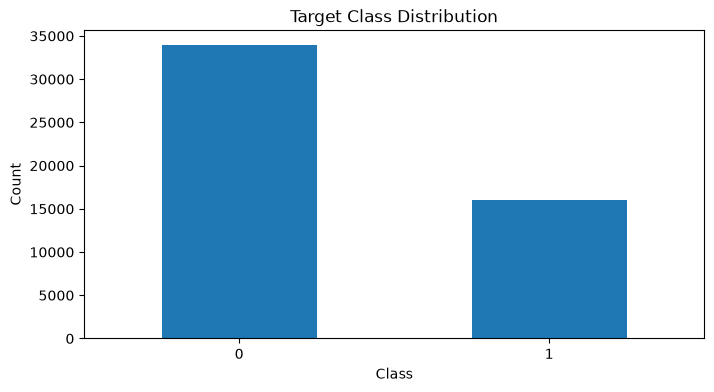


Target proportions:


Fraud_Label
0    0.67866
1    0.32134
Name: proportion, dtype: float64

In [4]:

print("Missing values (top 20):")
display(X.isnull().sum().sort_values(ascending=False).head(20))

plt.figure(figsize=(8, 4))
y.astype(str).value_counts().plot(kind="bar")
plt.title("Target Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

print("\nTarget proportions:")
display(y.astype(str).value_counts(normalize=True).rename("proportion"))


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# Target ko binary numeric labels mein convert karo.
# Binary classification required hai.
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y.astype(str))

if len(label_encoder.classes_) != 2:
    raise ValueError(
        f"Is code ko binary target chahiye. Classes mili hain: "
        f"{list(label_encoder.classes_)}"
    )

print("Class mapping:", dict(enumerate(label_encoder.classes_)))
print("Note: probability class 1 ki hogi:", label_encoder.classes_[1])

# Rare classes hon to stratify split ko possible rakhne ke liye
# har class mein kam az kam 2 records chahiye.
class_counts = pd.Series(y_encoded).value_counts()
if class_counts.min() < 2:
    raise ValueError("Har class mein kam az kam 2 rows honi chahiye.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))


Class mapping: {0: '0', 1: '1'}
Note: probability class 1 ki hogi: 1
Training shape: (40000, 20)
Testing shape: (10000, 20)
Numeric columns: 11
Categorical columns: 9


In [6]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

trained_pipelines = {}
comparison_results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, prob),
        "PR_AUC": average_precision_score(y_test, prob)
    }

    comparison_results.append(row)
    trained_pipelines[name] = pipeline

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values("PR_AUC", ascending=False)

display(comparison_df)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
1,Random Forest,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000
2,Extra Trees,0.9500,0.908954,0.938375,0.923430,0.990101,0.980507
0,Logistic Regression,0.7862,0.649847,0.725490,0.685588,0.885063,0.800034


Selected model: Random Forest

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6787
           1       1.00      1.00      1.00      3213

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



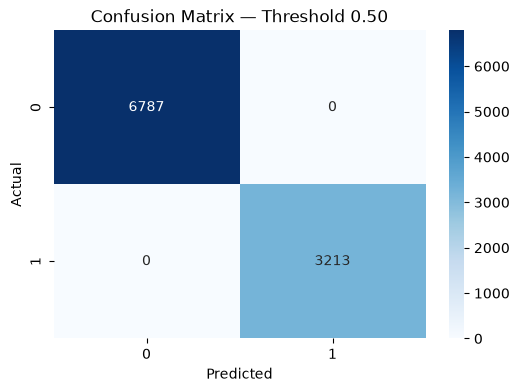

ROC-AUC: 1.0
PR-AUC: 1.0


In [7]:

best_name = comparison_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_name]

y_prob = best_pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.50).astype(int)

print("Selected model:", best_name)
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=[str(c) for c in label_encoder.classes_],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix — Threshold 0.50")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))


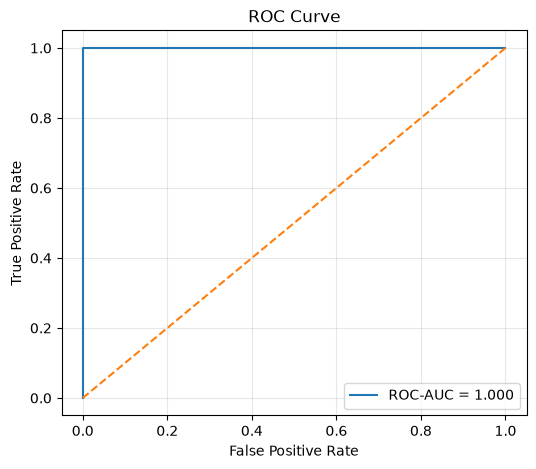

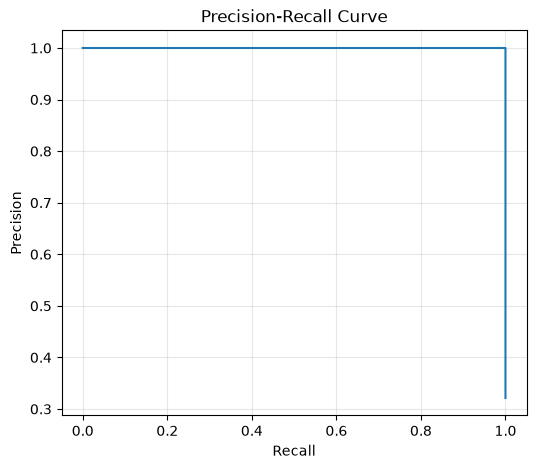

In [8]:

from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_test, y_prob):.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

precision, recall, _ = precision_recall_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(alpha=0.3)
plt.show()


In [9]:

risk_results = X_test.copy()

risk_results["actual_class"] = label_encoder.inverse_transform(y_test)
risk_results["risk_probability"] = y_prob
risk_results["predicted_class"] = label_encoder.inverse_transform(y_pred)

risk_results = risk_results.sort_values(
    "risk_probability",
    ascending=False
)

display(risk_results.head(20))

os.makedirs("project3_outputs", exist_ok=True)

comparison_df.to_csv(
    "project3_outputs/model_comparison.csv",
    index=False
)

risk_results.to_csv(
    "project3_outputs/risk_scored_test_records.csv",
    index=True
)

print("Risk scoring results exported.")


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Timestamp,Account_Balance,Device_Type,Location,Merchant_Category,IP_Address_Flag,...,Failed_Transaction_Count_7d,Card_Type,Card_Age,Transaction_Distance,Authentication_Method,Risk_Score,Is_Weekend,actual_class,risk_probability,predicted_class
35031,TXN_12420,USER_6297,109.12,Bank Transfer,2023-12-13 00:06:00,33990.63,Mobile,Tokyo,Electronics,0,...,4,Mastercard,142,1656.39,PIN,0.9120,1,1,0.905025,1
26200,TXN_5312,USER_9997,74.25,Bank Transfer,2023-08-29 06:10:00,72696.81,Mobile,Sydney,Clothing,0,...,4,Mastercard,107,722.35,Biometric,0.9378,0,1,0.904218,1
4689,TXN_44596,USER_9680,81.32,Bank Transfer,2023-05-29 05:24:00,59220.94,Laptop,Tokyo,Groceries,0,...,4,Mastercard,126,3276.93,Biometric,0.8688,0,1,0.903336,1
37418,TXN_9759,USER_9798,61.50,Online,2023-04-17 12:55:00,66916.99,Laptop,Tokyo,Travel,0,...,4,Visa,151,3524.42,OTP,0.9187,0,1,0.902831,1
9996,TXN_25079,USER_9664,157.64,Online,2023-07-30 11:13:00,31938.24,Tablet,Sydney,Electronics,0,...,4,Discover,35,3689.88,OTP,0.8991,0,1,0.902720,1
20265,TXN_35378,USER_7115,113.70,Bank Transfer,2023-05-09 12:26:00,66625.30,Mobile,Tokyo,Electronics,0,...,4,Visa,115,375.95,Biometric,0.9009,0,1,0.902439,1
46620,TXN_22760,USER_2755,71.09,Bank Transfer,2023-10-27 10:01:00,55232.05,Mobile,New York,Groceries,0,...,4,Amex,138,3301.28,PIN,0.8997,0,1,0.901809,1
9912,TXN_29449,USER_2412,299.67,Bank Transfer,2023-01-13 14:59:00,35028.73,Mobile,New York,Electronics,0,...,4,Mastercard,140,4127.23,PIN,0.9356,0,1,0.901125,1
25282,TXN_6508,USER_3544,30.72,Bank Transfer,2023-05-20 15:50:00,61289.72,Laptop,Sydney,Clothing,0,...,4,Amex,42,3424.54,Biometric,0.9702,0,1,0.898231,1
39096,TXN_32244,USER_9996,128.28,Bank Transfer,2023-11-06 10:22:00,64674.15,Laptop,Tokyo,Clothing,0,...,4,Discover,94,2853.04,Password,0.9595,0,1,0.897570,1


Risk scoring results exported.


In [10]:

joblib.dump(
    {
        "pipeline": best_pipeline,
        "feature_columns": X.columns.tolist(),
        "target_column": TARGET_COL,
        "label_encoder": label_encoder,
        "selected_model": best_name
    },
    "project3_outputs/credit_risk_model.joblib"
)

print("Project 3 complete!")
print("Files saved in project3_outputs/")


Project 3 complete!
Files saved in project3_outputs/
